# Problem 15 - Traveling Salesperson Problem (TSP)

## Stage 4 - Metric MST 2-Approximation

In Stages 1-3 we saw two exact methods (Brute Force and Held-Karp) and one fast heuristic (Nearest Neighbor).

- Exact methods always find the shortest route, but they become too slow when the number of cities grows.
- Nearest Neighbor is fast, but we have **no guarantee** how bad its route can be.

Stage 4 is fast **and** has a guarantee. It uses a **Minimum Spanning Tree (MST)** to build a route that is **never longer than 2 × the optimal route** (when the triangle inequality holds). This kind of algorithm is called a **2-approximation**.

## Basic Ideas

- **Graph:** cities are vertices, and the distance D[i][j] is the weight of the edge between city i and city j.
- **Tree:** a connected graph without cycles. A tree with n vertices always has exactly n − 1 edges.
- **Spanning tree:** a tree that connects all the cities.
- **Minimum Spanning Tree (MST):** the spanning tree with the smallest total weight. It is the cheapest way to connect all the cities (but it is not a route yet).
- **Triangle inequality:** D[a][c] ≤ D[a][b] + D[b][c]. Going directly is never longer than going through another city.

## Distance Matrix

We use the same 4-city matrix as in the previous stages.

In [1]:
D = [
    [0, 10, 15, 20],
    [10, 0, 35, 25],
    [15, 35, 0, 30],
    [20, 25, 30, 0]
]

print("Number of cities:", len(D))

Number of cities: 4


## Calculating the Total Route Distance

Same helper function as in Stage 1.

In [2]:
def route_cost(route, D):
    total = 0

    for i in range(len(route) - 1):
        from_city = route[i]
        to_city = route[i + 1]

        total += D[from_city][to_city]

    return total

## Step 1 - Building the MST with Prim's Algorithm

Prim's algorithm grows **one tree**, starting from city 0.

**How it works:**
1. Start with only city 0 in the tree.
2. Look at all edges that go **from a city in the tree to a city that is not in the tree yet**.
3. Take the cheapest of these edges and add the new city to the tree.
4. Repeat until all cities are in the tree.

We store two lists:
- `key[v]` - the cheapest edge found so far from the tree to city v,
- `parent[v]` - the tree city at the other end of that edge.

Each of the n steps scans all cities once, so the time complexity is **O(n²)**. This is the best choice for our problem, because every city is connected to every other city (a complete graph).

*Alternative: Kruskal's algorithm sorts all edges and adds them from the cheapest, skipping edges that would create a cycle. It takes O(n² log n) on a complete graph, so Prim is a better fit here.*

In [3]:
def prim_mst(D, start=0, show_steps=False):
    n = len(D)
    in_tree = [False] * n
    key = [float("inf")] * n     # cheapest edge from the tree to each city
    parent = [None] * n          # which tree city that edge comes from
    key[start] = 0

    mst_edges = []
    total = 0

    for step in range(n):
        # Pick the city outside the tree with the cheapest connecting edge
        u = None
        for v in range(n):
            if not in_tree[v] and (u is None or key[v] < key[u]):
                u = v

        in_tree[u] = True

        if parent[u] is not None:
            mst_edges.append((parent[u], u))
            total += D[parent[u]][u]
            if show_steps:
                print("Add edge", parent[u], "-", u, "weight:", D[parent[u]][u])

        # Update the cheapest edges for cities that are not in the tree yet
        for v in range(n):
            if not in_tree[v] and D[u][v] < key[v]:
                key[v] = D[u][v]
                parent[v] = u

    return mst_edges, total


mst_edges, mst_cost = prim_mst(D, show_steps=True)

print("\nMST edges:", mst_edges)
print("MST cost:", mst_cost)

Add edge 0 - 1 weight: 10
Add edge 0 - 2 weight: 15
Add edge 0 - 3 weight: 20

MST edges: [(0, 1), (0, 2), (0, 3)]
MST cost: 45


## Checking the Bounds: MST ≤ OPT ≤ 2 · MST

**Why is MST ≤ OPT?** If we remove one edge from the optimal route, we get a path that visits every city. A path is also a spanning tree, and the MST is the cheapest spanning tree. So MST ≤ OPT.

From Stage 1 (Brute Force) we know that OPT = 80.

In [4]:
OPT = 80   # optimal distance found by Brute Force in Stage 1

print("MST cost:", mst_cost)
print("OPT:", OPT)
print("2 * MST:", 2 * mst_cost)
print("MST <= OPT <= 2 * MST:", mst_cost <= OPT <= 2 * mst_cost)

MST cost: 45
OPT: 80
2 * MST: 90
MST <= OPT <= 2 * MST: True


## Step 2 - Walking Around the Tree (DFS Preorder)

Now we turn the tree into a route.

1. We do a **Depth-First Search (DFS)** from city 0 and write down every city the **first time** we visit it. This order is called **preorder**.
2. We add city 0 at the end to close the route.

DFS is written with **recursion**: visit a city, then visit all its children one by one. (The same can be done with a **stack**, using Push and Pop.)

**Why does this work?** A full walk around the tree goes along every edge twice (down and back), so its length is **2 · MST**. Preorder is the same walk, but we **skip cities we have already visited** and go straight to the next new city. This is called **shortcutting**.

In [5]:
def build_children(mst_edges, n):
    # For each city, the list of its children in the tree
    children = [[] for _ in range(n)]
    for parent, child in mst_edges:
        children[parent].append(child)
    return children


def dfs_preorder(city, children, order):
    order.append(city)               # write the city down on the first visit
    for child in children[city]:
        dfs_preorder(child, children, order)
    return order


def full_walk(city, children, walk):
    # Walk around the tree and come back along every edge
    walk.append(city)
    for child in children[city]:
        full_walk(child, children, walk)
        walk.append(city)            # come back to the parent
    return walk


children = build_children(mst_edges, len(D))
walk = full_walk(0, children, [])
order = dfs_preorder(0, children, [])

print("Children of each city:", children)
print("Full walk:", walk, "Distance:", route_cost(walk, D))
print("Preorder:", order)

Children of each city: [[1, 2, 3], [], [], []]
Full walk: [0, 1, 0, 2, 0, 3, 0] Distance: 90
Preorder: [0, 1, 2, 3]


## Step 3 - The MST Approximation Route

We put all steps together: build the MST, take the preorder, and return to the start.

In [6]:
def mst_approximation(D, start=0):
    n = len(D)

    # Step 1: build the MST
    mst_edges, mst_cost = prim_mst(D, start)

    # Step 2: DFS preorder of the tree
    children = build_children(mst_edges, n)
    order = dfs_preorder(start, children, [])

    # Step 3: return to the starting city
    route = order + [start]
    total_distance = route_cost(route, D)

    return route, total_distance


route, distance = mst_approximation(D)

print("MST Approximation Route:", route)
print("Total Distance:", distance)

MST Approximation Route: [0, 1, 2, 3, 0]
Total Distance: 95


## Why is the Route at Most 2 × OPT?

The guarantee follows from three simple facts:

1. **MST ≤ OPT.** If we remove one edge from the optimal route, we get a tree. The MST is the cheapest tree.
2. **Full walk = 2 · MST.** The full walk uses every tree edge twice.
3. **Route ≤ full walk.** Skipping a visited city never makes the route longer, because of the **triangle inequality**: D[a][c] ≤ D[a][b] + D[b][c].

So: **route ≤ 2 · MST ≤ 2 · OPT.**

*Note: our small 4-city matrix does not fully satisfy the triangle inequality (D[1][2] = 35 > 10 + 15), so here the route (95) is a bit above 2 · MST = 90. The guarantee 95 ≤ 2 · OPT = 160 still holds. Real map distances always satisfy the triangle inequality, so next we test the algorithm on random map cities.*

## Experiment 1 - Random Cities on a Map (Metric Case)

We generate 20 random sets of 10 cities with (x, y) coordinates. The distance is the normal straight-line (Euclidean) distance, so the triangle inequality always holds.

For each set we compute:
- **OPT** with Brute Force (from Stage 1),
- the route of **Nearest Neighbor** (Stage 2),
- the route of **MST Approximation** (Stage 4),

and the **approximation ratio** = route / OPT (1.00 means optimal).

In [7]:
import math
import random
from itertools import permutations


def random_cities(n, seed):
    rng = random.Random(seed)
    return [(rng.uniform(0, 100), rng.uniform(0, 100)) for _ in range(n)]


def distance_matrix(points):
    n = len(points)
    return [[math.dist(points[i], points[j]) for j in range(n)] for i in range(n)]


# Stage 1 - Brute Force (same code as in Stage 1)
def brute_force(D):
    n = len(D)
    best_distance = float("inf")
    best_route = []
    for order in permutations(range(1, n)):
        if len(order) > 1 and order[0] > order[-1]:
            continue
        route = [0] + list(order) + [0]
        distance = route_cost(route, D)
        if distance < best_distance:
            best_distance = distance
            best_route = route
    return best_route, best_distance


# Stage 2 - Nearest Neighbor (same code as in Stage 2)
def nearest_neighbor(D, start=0):
    n = len(D)
    route = [start]
    unvisited = list(range(n))
    unvisited.remove(start)
    current = start
    while unvisited:
        next_city = min(unvisited, key=lambda city: D[current][city])
        route.append(next_city)
        unvisited.remove(next_city)
        current = next_city
    route.append(start)
    return route, route_cost(route, D)

In [8]:
n = 10
mst_ratios = []
nn_ratios = []

print(f"{'Test':>4} {'OPT':>8} {'NN':>8} {'MST':>8} {'NN/OPT':>8} {'MST/OPT':>8} {'MST<=2*OPT':>11}")

for seed in range(20):
    D_test = distance_matrix(random_cities(n, seed))

    _, opt = brute_force(D_test)
    _, nn = nearest_neighbor(D_test)
    _, mst = mst_approximation(D_test)

    nn_ratios.append(nn / opt)
    mst_ratios.append(mst / opt)

    print(f"{seed + 1:>4} {opt:>8.1f} {nn:>8.1f} {mst:>8.1f} {nn / opt:>8.2f} {mst / opt:>8.2f} {str(mst <= 2 * opt):>11}")

print()
print(f"Nearest Neighbor:  average ratio {sum(nn_ratios) / len(nn_ratios):.2f}, worst {max(nn_ratios):.2f}")
print(f"MST Approximation: average ratio {sum(mst_ratios) / len(mst_ratios):.2f}, worst {max(mst_ratios):.2f}")

Test      OPT       NN      MST   NN/OPT  MST/OPT  MST<=2*OPT
   1    239.4    267.7    267.7     1.12     1.12        True


   2    344.8    359.9    376.7     1.04     1.09        True


   3    301.1    374.2    374.2     1.24     1.24        True


   4    304.8    310.9    377.1     1.02     1.24        True


   5    289.2    306.6    386.2     1.06     1.34        True


   6    343.2    392.9    445.0     1.14     1.30        True


... (10 outputs left out)

  17    307.7    307.7    344.9     1.00     1.12        True


  18    323.2    335.5    426.7     1.04     1.32        True


  19    255.3    290.6    290.6     1.14     1.14        True


  20    233.5    265.7    265.7     1.14     1.14        True

Nearest Neighbor:  average ratio 1.08, worst 1.29
MST Approximation: average ratio 1.17, worst 1.34


In every test the MST route stays below 2 · OPT, as the proof promises. In practice it is usually much closer to the optimum than the worst case of 2×.

Nearest Neighbor is often a bit shorter on average, but it has **no guarantee**. The MST route always has one.

## Experiment 2 - Drawing the MST and the Route (100 Cities)

With 100 cities Brute Force is impossible (99!/2 routes), but the MST approximation finishes instantly.

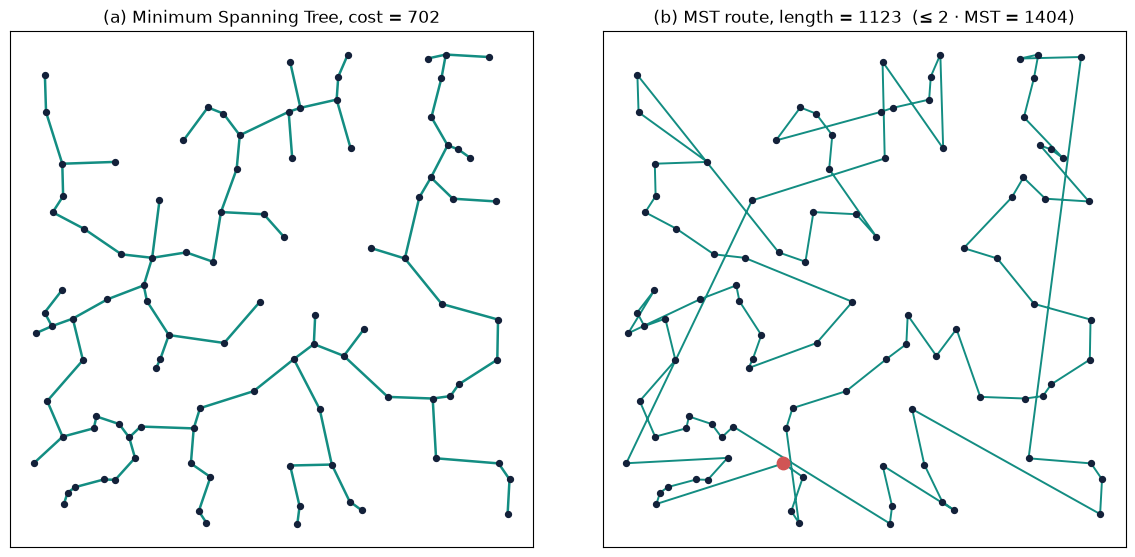

In [9]:
import matplotlib.pyplot as plt

points = random_cities(100, seed=7)
D_big = distance_matrix(points)

big_edges, big_mst_cost = prim_mst(D_big)
big_route, big_route_cost = mst_approximation(D_big)

xs = [p[0] for p in points]
ys = [p[1] for p in points]

fig, axes = plt.subplots(1, 2, figsize=(12, 5.6))

# (a) the MST
ax = axes[0]
for a, b in big_edges:
    ax.plot([xs[a], xs[b]], [ys[a], ys[b]], color="#138D82", linewidth=1.8)
ax.scatter(xs, ys, s=18, color="#13213A", zorder=3)
ax.set_title(f"(a) Minimum Spanning Tree, cost = {big_mst_cost:.0f}")

# (b) MST approximation route
ax = axes[1]
ax.plot([xs[c] for c in big_route], [ys[c] for c in big_route], color="#138D82", linewidth=1.4)
ax.scatter(xs, ys, s=18, color="#13213A", zorder=3)
ax.scatter([xs[0]], [ys[0]], s=80, color="#D05555", zorder=4)
ax.set_title(f"(b) MST route, length = {big_route_cost:.0f}  (≤ 2 · MST = {2 * big_mst_cost:.0f})")

for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect("equal")

plt.tight_layout()
plt.savefig("stage4_mst_100_cities.png", dpi=160, bbox_inches="tight")
plt.show()

The route stays below 2 · MST, and since MST ≤ OPT, it is also below 2 · OPT. The red dot is the start city.

The route still has some **crossing edges**. Removing them is exactly what Stage 5 (2-Opt) does.

## Performance Measurement

We measure two things, like in Stage 3:
- **Execution time** with `time.perf_counter()`.
- **Peak memory** with `tracemalloc` (the largest amount of Python memory the algorithm allocates while it runs).

First we measure the 4-city example.

In [10]:
import time
import tracemalloc

tracemalloc.start()
start_time = time.perf_counter()

route, distance = mst_approximation(D)

execution_time = time.perf_counter() - start_time
_, peak_memory = tracemalloc.get_traced_memory()
tracemalloc.stop()

print("Route:", route, "Distance:", distance)
print(f"Execution time: {execution_time:.6f} seconds")
print(f"Peak memory usage: {peak_memory / 1024:.2f} KB")

Route: [0, 1, 2, 3, 0] Distance: 95
Execution time: 0.000135 seconds
Peak memory usage: 19.11 KB


### How Time and Memory Grow with More Cities

Now we run the MST approximation on bigger random maps. Time and memory are measured in separate runs, because `tracemalloc` slows the code down. For the time we take the best of 3 runs, so the result is more stable.

The distance matrix is created **before** the measurement, so we only measure the algorithm itself.

In [11]:
def measure_time(D, runs=3):
    best = float("inf")
    for _ in range(runs):
        start_time = time.perf_counter()
        mst_approximation(D)
        best = min(best, time.perf_counter() - start_time)
    return best


def measure_memory(D):
    tracemalloc.start()
    mst_approximation(D)
    _, peak_memory = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return peak_memory


sizes = [50, 100, 200, 400, 800]
times = []
memories = []

print(f"{'Cities':>6} {'Time (s)':>10} {'Time x':>8} {'Memory (KB)':>12}")

for n in sizes:
    D_test = distance_matrix(random_cities(n, seed=1))
    t = measure_time(D_test)
    m = measure_memory(D_test)

    growth = f"{t / times[-1]:.1f}" if times else "-"
    times.append(t)
    memories.append(m)

    print(f"{n:>6} {t:>10.4f} {growth:>8} {m / 1024:>12.1f}")

Cities   Time (s)   Time x  Memory (KB)
    50     0.0001        -          3.2
   100     0.0004      3.4          7.4
   200     0.0017      3.9         18.1
   400     0.0068      4.1         45.4


   800     0.0308      4.5        103.3


**Time:** every time the number of cities doubles, the time grows about **4 times** (column "Time x"). This is exactly what O(n²) means: (2n)² = 4n². Even 800 cities take well under a second.

**Memory:** the algorithm only stores a few lists of length n (`key`, `parent`, `in_tree`, the tree and the route), so the extra memory grows only **linearly**, O(n). The n × n distance matrix is the input, so it is not counted here.

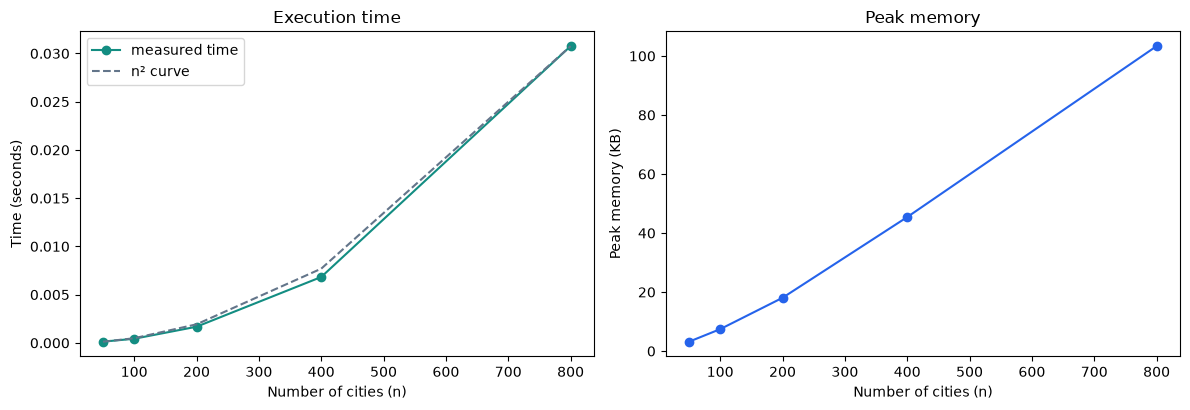

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

ax = axes[0]
ax.plot(sizes, times, marker="o", color="#138D82", label="measured time")
ax.plot(sizes, [times[-1] * (s / sizes[-1]) ** 2 for s in sizes], linestyle="--", color="#63758A", label="n² curve")
ax.set_xlabel("Number of cities (n)")
ax.set_ylabel("Time (seconds)")
ax.set_title("Execution time")
ax.legend()

ax = axes[1]
ax.plot(sizes, [m / 1024 for m in memories], marker="o", color="#2563EB")
ax.set_xlabel("Number of cities (n)")
ax.set_ylabel("Peak memory (KB)")
ax.set_title("Peak memory")

plt.tight_layout()
plt.show()

The measured time follows the n² curve, and the memory grows in a straight line.

## Conclusion

| Algorithm | Optimal? | Guarantee | Time complexity | Space complexity |
|---|---|---|---|---|
| Brute Force | Yes | Exact | O(n!) | O(n) |
| Nearest Neighbor | No | None | O(n²) | O(n) |
| Held-Karp | Yes | Exact | O(n² · 2ⁿ) | O(n · 2ⁿ) |
| MST Approximation | No | ≤ 2 · OPT | O(n²) | O(n) |

**MST Approximation:** build a Minimum Spanning Tree with Prim's algorithm, walk around it with DFS, and skip cities that are already visited.

- **Advantages:** fast (O(n²)), works for thousands of cities, and **guarantees** a route at most 2× the optimum.
- **Disadvantages:** usually not optimal, and the route can have crossing edges.

The MST route is a good **starting point** for Stage 5 (2-Opt), which improves it by removing crossings.